# Ince-Gaussian beams

The paraxial wave equation separates in three coordinate systems, and each
gives a complete family of beams that keep their shape on propagation:
Cartesian coordinates give the **Hermite-Gaussian** (HG) modes, circular
cylinder coordinates the **Laguerre-Gaussian** (LG) modes, and elliptic
cylinder coordinates the **Ince-Gaussian** (IG) modes found by Bandres and
Gutiérrez-Vega in 2004. IG modes have one extra parameter, the ellipticity
$\varepsilon$, and interpolate between the other two: for $\varepsilon \to 0$
they become LG modes, for $\varepsilon \to \infty$ HG modes. They are not
only a mathematical curiosity: a stable laser resonator whose rotational
symmetry is slightly broken (a tilted crystal, a slightly elliptic pump)
oscillates on IG modes (Schwarz et al. 2004).

This notebook builds them with `pyoptics.ince` and answers the question
whether they go through ABCD systems as nicely as HG and LG modes do:

1. elliptic coordinates and the Ince polynomials, computed as a small
   eigenvalue problem,
2. a mode gallery from $\varepsilon \to 0$ to $\varepsilon \to \infty$ and a
   check of orthonormality,
3. IG modes as finite sums of HG and LG modes of one order, against the
   numerical decomposition of notebook [09 (mode analysis)](09_mode_analysis.ipynb),
4. free-space propagation and the Gouy phase $(p+1)\psi$,
5. through ABCD systems: a focusing lens and a lens waveguide,
6. helical IG modes, whose vortices sit on the line between the foci,
7. where it stops: a cylindrical lens.

**The short answer to the ABCD question:** yes, in every system that treats
$x$ and $y$ alike (rotationally symmetric, or any isotropic $2\times 2$
matrix). An IG mode of order $p$ is a sum of HG (or LG) modes of the same
order $N = p$, which all pick up the same Gouy phase $(p+1)\psi$. So the
whole pattern is carried along: transform $q$ with the ABCD law, scale the
pattern with $w(z)$ and keep $\varepsilon$. In an astigmatic system,
$\mathrm{HG}_{lm}$ picks up $(l+\frac12)\psi_x + (m+\frac12)\psi_y$, the parts
drift out of phase and the IG pattern falls apart (section 7). General
astigmatic systems, with rotated cylindrical lenses, are the subject of
notebook [08 (ABCD matrices)](08_abcd_matrices.ipynb), sections 11 and 12.

The HG and LG modes come from notebook [06 (Gaussian beams)](06_gaussian_beams.ipynb), the vortex tools
from notebook [69 (optical vortices)](69_optical_vortices.ipynb). Lengths are in mm, the wavelength is
632.8 nm, the waist of the underlying Gaussian beam is $w_0 = 1$ mm. All fields
use the pyoptics convention $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$.

In [1]:
import time
from math import factorial

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import eval_hermite

from pyoptics import abcd, ince, modes, vortices
from pyoptics.propagators import fresnel_TF
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "image.origin": "lower",
                     "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()

WL = 632.8e-6                   # HeNe (mm)
W0 = 1.0                        # waist radius of the underlying Gaussian (mm)
Z_R = np.pi*W0**2/WL            # Rayleigh length (4.97 m)
x, y, X, Y = grid2d(-5, 5, -5, 5, 256)
dA = (x[1] - x[0])**2
EXT = [x[0], x[-1], y[0], y[-1]]


def overlap(u, v):
    return np.sum(u*np.conj(v))*dA


def show_I(ax, u, title=None, lim=3.5, foci=None):
    I = np.abs(u)**2
    ax.imshow(I/I.max(), extent=EXT, cmap="magma", vmin=0, vmax=1)
    if foci is not None:
        ax.plot([-foci, foci], [0, 0], "c+", ms=8, mew=1.5)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=10)


def show_phase(ax, u, title=None, lim=3.5, threshold=1e-3):
    I = np.abs(u)**2
    phase = np.where(I > threshold*I.max(), np.angle(u), np.nan)
    ax.imshow(phase, extent=EXT, cmap="twilight", vmin=-np.pi, vmax=np.pi)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=10)


def label(parity, p, m, eps=None):
    s = r"IG$^{%s}_{%d,%d}$" % ("e" if parity == "even" else "o", p, m)
    return s if eps is None else s + r", $\varepsilon$ = %g" % eps

## 1. Elliptic coordinates and Ince polynomials

Elliptic coordinates $(\xi, \eta)$ with the foci at $x = \pm f$ are

$$x = f\cosh\xi\cos\eta, \qquad y = f\sinh\xi\sin\eta, \qquad \xi \ge 0,\ 0 \le \eta < 2\pi .$$

Lines of constant $\xi$ are confocal ellipses, lines of constant $\eta$
confocal hyperbolas. For an IG beam the foci move apart with the beam,
$f(z) = f_0\,w(z)/w_0$, and the **ellipticity parameter**
$\varepsilon = 2f_0^2/w_0^2$ stays constant. The modes are

$$\mathrm{IG}^e_{p,m} = C_p^m(i\xi, \varepsilon)\,C_p^m(\eta, \varepsilon)\,
\frac{w_0}{w}e^{-r^2/w^2}\,e^{i(kz + kr^2/2R - (p+1)\psi)},$$

and $\mathrm{IG}^o_{p,m}$ with $S_p^m$ in place of $C_p^m$. $p$ is the order, and
$m$ has the parity of $p$, $0 \le m \le p$ for the even and $1 \le m \le p$ for the
odd modes. $C_p^m$ and $S_p^m$ are **Ince polynomials**, the periodic solutions
of the Ince equation

$$C'' + \varepsilon\sin(2\eta)\,C' + (a - p\,\varepsilon\cos 2\eta)\,C = 0 .$$

The equation couples $\cos n\eta$ only to $\cos(n\pm2)\eta$, and the coupling
to $n = p + 2$ vanishes. So the solutions are finite Fourier series up to
$\cos p\eta$ (or $\sin p\eta$), and the eigenvalues $a$ of a matrix of size
about $p/2$ give all of them. `ince.ince_series()` sets up that matrix and
sorts the eigenvectors by $a$: as $\varepsilon \to 0$, the one with index $m$
becomes $\cos m\eta$ ($\sin m\eta$) with $a = m^2$.

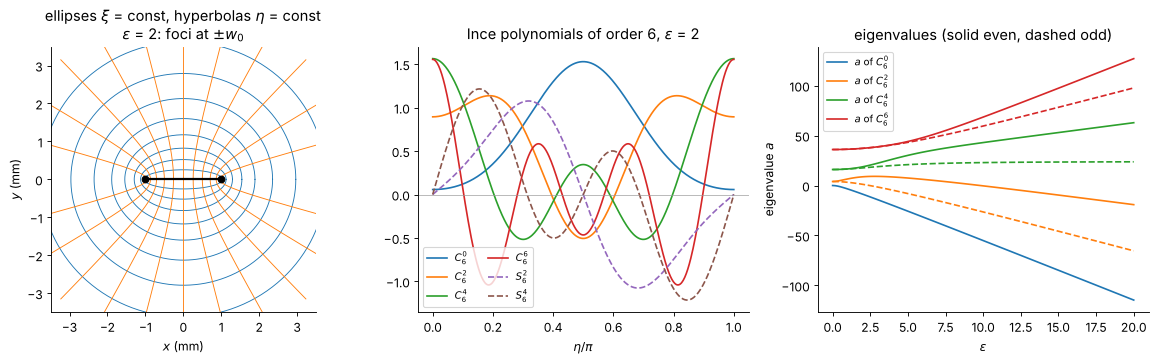

In [2]:
eps_demo = 2.0
f0 = np.sqrt(eps_demo/2)*W0
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
ax = axes[0]
t = np.linspace(0, 2*np.pi, 400)
for xi in np.linspace(0.25, 2.0, 8):
    ax.plot(f0*np.cosh(xi)*np.cos(t), f0*np.sinh(xi)*np.sin(t), color="C0", lw=0.8)
s = np.linspace(0, 2.2, 200)
for eta in np.arange(1, 12)*np.pi/12:
    if abs(eta - np.pi/2) < 1e-9:
        ax.axvline(0, color="C1", lw=0.8)
        continue
    for sign in (1, -1):
        ax.plot(f0*np.cosh(s)*np.cos(eta), sign*f0*np.sinh(s)*np.sin(eta), color="C1", lw=0.8)
ax.plot([-f0, f0], [0, 0], "k", lw=2)
ax.plot([-f0, f0], [0, 0], "ko")
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_aspect("equal")
ax.set_title(r"ellipses $\xi$ = const, hyperbolas $\eta$ = const" + "\n" + r"$\varepsilon$ = 2: foci at $\pm w_0$")
ax.set_xlabel("$x$ (mm)"); ax.set_ylabel("$y$ (mm)")

ax = axes[1]
eta = np.linspace(0, np.pi, 400)
for m in (0, 2, 4, 6):
    ax.plot(eta/np.pi, ince.ince_polynomial(6, m, eps_demo, eta), label=r"$C_6^{%d}$" % m)
for m in (2, 4):
    ax.plot(eta/np.pi, ince.ince_polynomial(6, m, eps_demo, eta, "odd"), "--", label=r"$S_6^{%d}$" % m)
ax.axhline(0, color="0.6", lw=0.6)
ax.set_xlabel(r"$\eta/\pi$"); ax.set_title(r"Ince polynomials of order 6, $\varepsilon$ = 2")
ax.legend(ncol=2, fontsize=9)

ax = axes[2]
eps_axis = np.linspace(0, 20, 121)
for m in (0, 2, 4, 6):
    ax.plot(eps_axis, [ince.ince_series(6, m, e).a for e in eps_axis], color="C%d" % (m//2),
            label=r"$a$ of $C_6^{%d}$" % m)
for m in (2, 4, 6):
    ax.plot(eps_axis, [ince.ince_series(6, m, e, "odd").a for e in eps_axis], "--", color="C%d" % (m//2))
ax.set_xlabel(r"$\varepsilon$"); ax.set_ylabel("eigenvalue $a$")
ax.set_title("eigenvalues (solid even, dashed odd)")
ax.legend(fontsize=9)
fig.tight_layout()

The polynomial of index $m$ has $m$ zeros in $0 \le \eta < \pi$ (the dark
hyperbolas of the mode), and $C_p^m(i\xi)$ adds $(p-m)/2$ dark ellipses. The
eigenvalues of even and odd polynomials with the same $m$ start together at
$m^2$ and split as $\varepsilon$ grows.

## 2. A gallery from LG to HG

`ince.ig_mode()` returns the modes normalized to unit power. At
$\varepsilon = 10^{-3}$ the foci almost coincide and the modes are the
real LG combinations $\mathrm{LG}_{(p-m)/2,\,\pm m}$ added
($\cos m\varphi$, even) or subtracted ($\sin m\varphi$, odd). At
$\varepsilon = 1000$ the foci are far outside and the modes are
$\mathrm{HG}_{m,\,p-m}$ (even) and $\mathrm{HG}_{m-1,\,p-m+1}$ (odd), with
indices in $x$ and $y$. In between, the dark lines are ellipses and
hyperbolas around the foci (marked +).

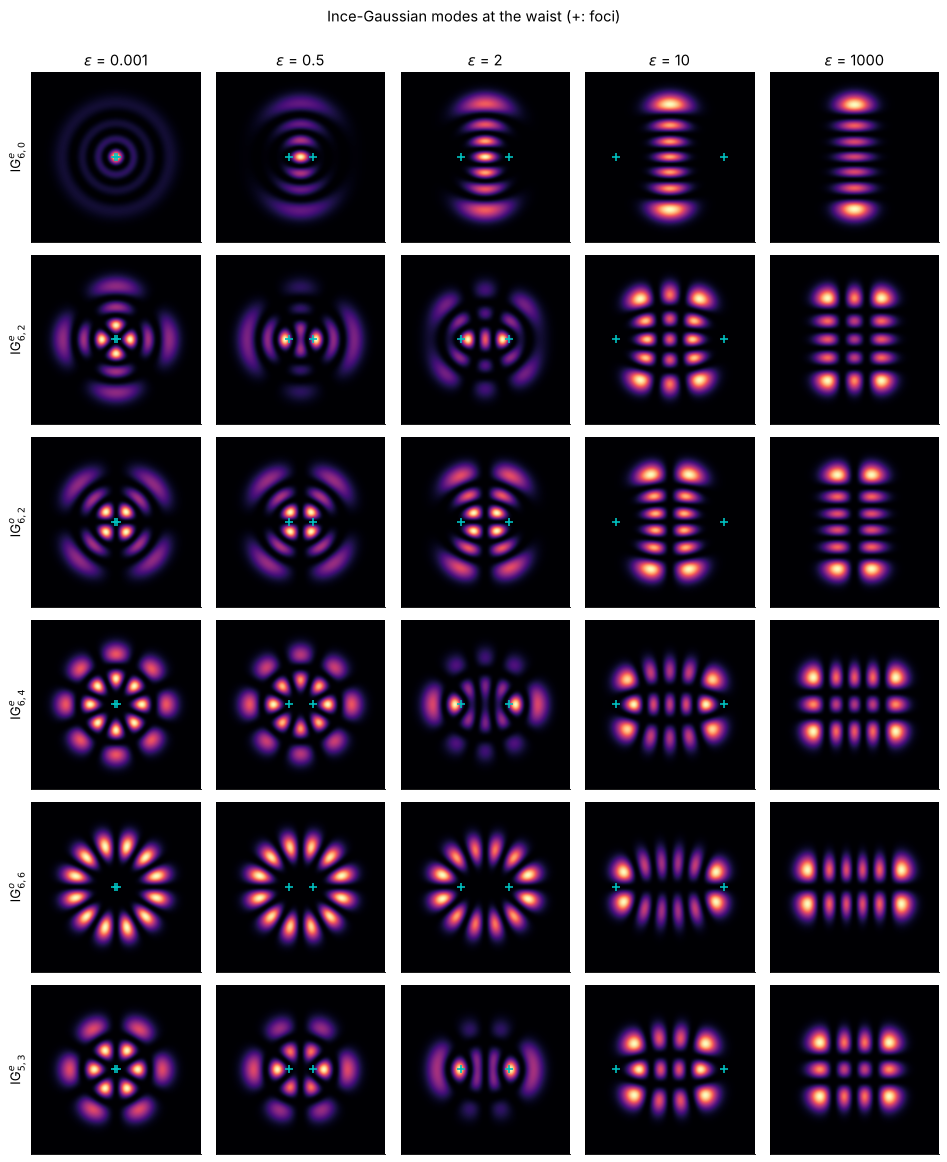

In [3]:
rows = [("even", 6, 0), ("even", 6, 2), ("odd", 6, 2), ("even", 6, 4), ("odd", 6, 6), ("even", 5, 3)]
eps_cols = [1e-3, 0.5, 2.0, 10.0, 1e3]
fig, axes = plt.subplots(len(rows), len(eps_cols), figsize=(12, 14.5))
for i, (parity, p, m) in enumerate(rows):
    for j, eps in enumerate(eps_cols):
        u = ince.ig_mode(p, m, eps, x, y, W0, WL, parity=parity)
        f = np.sqrt(eps/2)*W0
        show_I(axes[i, j], u, foci=f if f < 3.5 else None)
        if i == 0:
            axes[i, j].set_title(r"$\varepsilon$ = %g" % eps)
    axes[i, 0].set_ylabel(label(parity, p, m), fontsize=12)
fig.suptitle("Ince-Gaussian modes at the waist (+: foci)", y=1.0)
fig.tight_layout()

In [4]:
fields, names = [], []
for parity in ("even", "odd"):
    for p, m in ince.ince_indices(6, parity):
        fields.append(ince.ig_mode(p, m, 2.0, x, y, W0, WL, parity=parity))
        names.append((parity, p, m))
G = np.array([[overlap(u, v) for v in fields] for u in fields])
print("{} modes up to p = 6 (as many as HG modes: {})".format(len(fields), len(modes.hg_indices(6))))
print("largest deviation of the Gram matrix from the identity: {:.1e}".format(np.abs(G - np.eye(len(fields))).max()))

28 modes up to p = 6 (as many as HG modes: 28)
largest deviation of the Gram matrix from the identity: 1.5e-14


Even and odd modes up to order 6 at $\varepsilon = 2$ are orthonormal to the
rounding error. There are as many of them as there are HG (or LG) modes of the same orders,
so they form a complete basis too.

## 3. IG modes are sums of HG and LG modes of one order

The polynomial part $C_p^m(i\xi)C_p^m(\eta)$ is a polynomial of degree $p$ in
$x$ and $y$. Times the Gaussian, it is a combination of HG modes of order
$p$ only. `ince.hg_coefficients()` and `ince.lg_coefficients()` compute the
expansion exactly with Gauss-Hermite quadrature (for a polynomial of degree
$2p$ times $e^{-2r^2/w_0^2}$, $p+2$ nodes per axis are exact). We follow the
weights of $\mathrm{IG}^e_{6,2}$ from $\varepsilon \to 0$ to $\infty$, and compare
the coefficients with `modes.decompose_hg()` and `modes.decompose_lg()` from
notebook [09 (mode analysis)](09_mode_analysis.ipynb), applied to the sampled
field.

decompose_hg against the exact coefficients: max error 1.1e-13
decompose_lg against the exact coefficients: max error 8.0e-14
power outside the order p = 6: 1.6e-26


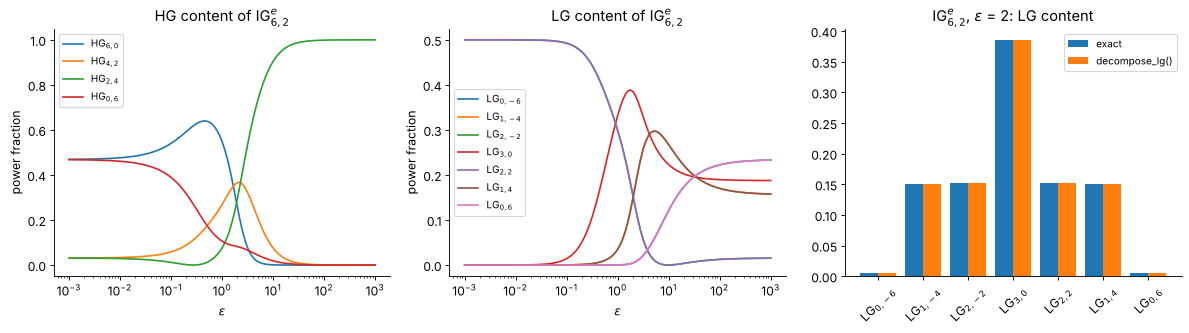

In [5]:
p, m = 6, 2
eps_axis = np.geomspace(1e-3, 1e3, 121)
hg_keys = [(l, p - l) for l in range(p, -1, -1)]
lg_keys = [((p - abs(l))//2, l) for l in range(-p, p + 1, 2)]
hg_w = np.array([[abs(ince.hg_coefficients(p, m, e)[k])**2 for k in hg_keys] for e in eps_axis])
lg_w = np.array([[abs(ince.lg_coefficients(p, m, e)[k])**2 for k in lg_keys] for e in eps_axis])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for j, k in enumerate(hg_keys):
    if hg_w[:, j].max() > 1e-3:
        axes[0].plot(eps_axis, hg_w[:, j], label=r"HG$_{%d,%d}$" % k)
for j, k in enumerate(lg_keys):
    if lg_w[:, j].max() > 1e-3:
        axes[1].plot(eps_axis, lg_w[:, j], label=r"LG$_{%d,%d}$" % k)
for ax, t in zip(axes[:2], ["HG content", "LG content"]):
    ax.set_xscale("log"); ax.set_xlabel(r"$\varepsilon$"); ax.set_ylabel("power fraction")
    ax.set_title(t + r" of IG$^e_{6,2}$"); ax.legend(fontsize=9)

# numerical decomposition of the sampled mode against the exact coefficients
eps = 2.0
u = ince.ig_mode(p, m, eps, x, y, W0, WL)
dec_hg = modes.decompose_hg(u, x, y, w0=W0, wavelength=WL, max_order=8)
dec_lg = modes.decompose_lg(u, x, y, w0=W0, wavelength=WL, max_order=8)
exact_hg, exact_lg = ince.hg_coefficients(p, m, eps), ince.lg_coefficients(p, m, eps)
err_hg = max(abs(dec_hg.coefficients[k] - exact_hg.get(k, 0)) for k in dec_hg.coefficients)
err_lg = max(abs(dec_lg.coefficients[k] - exact_lg.get(k, 0)) for k in dec_lg.coefficients)
print("decompose_hg against the exact coefficients: max error {:.1e}".format(err_hg))
print("decompose_lg against the exact coefficients: max error {:.1e}".format(err_lg))
other_orders = sum(f for k, f in dec_hg.power_fractions.items() if sum(k) != p)
print("power outside the order p = 6: {:.1e}".format(other_orders))

keys = sorted(exact_lg, key=lambda k: k[1])
axes[2].bar(np.arange(len(keys)) - 0.2, [abs(exact_lg[k])**2 for k in keys], 0.4, label="exact")
axes[2].bar(np.arange(len(keys)) + 0.2, [dec_lg.power_fractions[k] for k in keys], 0.4,
            label="decompose_lg()")
axes[2].set_xticks(range(len(keys)))
axes[2].set_xticklabels([r"LG$_{%d,%d}$" % k for k in keys], rotation=45)
axes[2].set_title(r"IG$^e_{6,2}$, $\varepsilon$ = 2: LG content"); axes[2].legend(fontsize=9)
fig.tight_layout()

At $\varepsilon \to 0$ the LG content is $\mathrm{LG}_{2,\pm2}$ in equal
parts, at $\varepsilon \to \infty$ the HG content is $\mathrm{HG}_{2,4}$ alone.
The numerical decomposition agrees with the exact coefficients to
$10^{-13}$, and no power leaks into other orders: every IG mode is a
superposition of modes from **one** order $N = p$.

## 4. Free-space propagation and the Gouy phase

All parts of the sum have the Gouy phase $(N+1)\psi = (p+1)\psi$, so the sum
keeps its shape and only grows with $w(z)$. We propagate
$\mathrm{IG}^o_{5,3}$ numerically with the Fresnel transfer function and
compare it with the analytic mode at the same $z$. The phase plots show the
wavefront curvature that the beam picks up on the way.

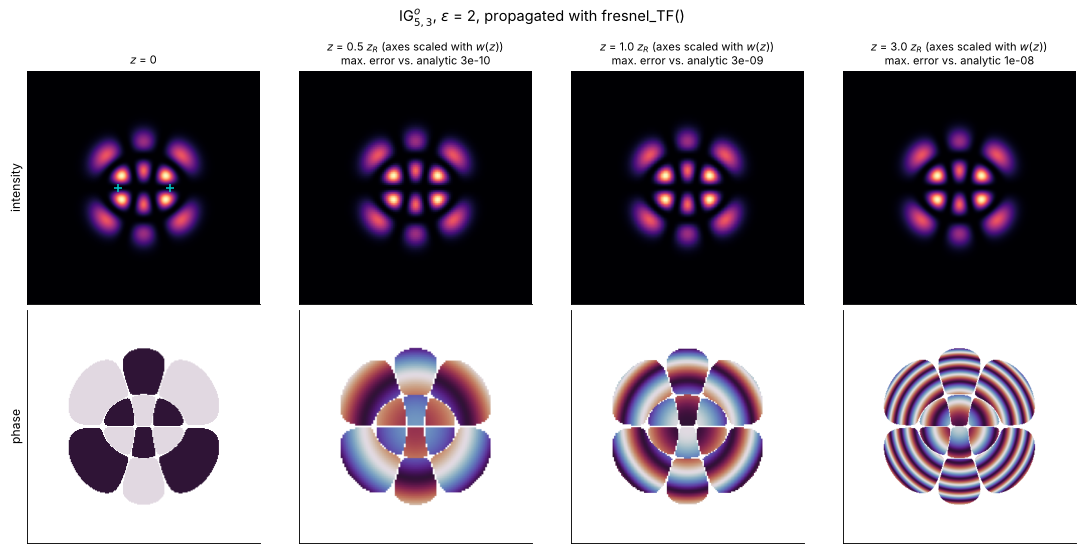

In [6]:
p, m, eps = 5, 3, 2.0
u0 = ince.ig_mode(p, m, eps, x, y, W0, WL, parity="odd")
z_show = np.array([0.5, 1.0, 3.0])*Z_R
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
show_I(axes[0, 0], u0, "$z$ = 0", lim=4.5, foci=np.sqrt(eps/2)*W0)
show_phase(axes[1, 0], u0, lim=4.5)
xb, yb, _, _ = grid2d(-20, 20, -20, 20, 512)     # wider window for 3 z_R
u0b = ince.ig_mode(p, m, eps, xb, yb, W0, WL, parity="odd")
for j, z in enumerate(z_show):
    u, _, _ = fresnel_TF(u0b, xb, yb, z, WL)
    ref = ince.ig_mode(p, m, eps, xb, yb, W0, WL, z=z, parity="odd")
    w = W0*np.sqrt(1 + (z/Z_R)**2)
    err = np.abs(u - ref).max()/np.abs(ref).max()
    for ax, img, cmap, vr in ((axes[0, j + 1], np.abs(u)**2, "magma", (0, None)),
                              (axes[1, j + 1], np.angle(u), "twilight", (-np.pi, np.pi))):
        if cmap == "twilight":
            img = np.where(np.abs(u)**2 > 1e-3*np.abs(u).max()**2, img, np.nan)
        ax.imshow(img/(img.max() if cmap == "magma" else 1), extent=[xb[0]/w, xb[-1]/w, yb[0]/w, yb[-1]/w],
                  cmap=cmap, vmin=vr[0] if cmap == "twilight" else 0, vmax=vr[1] if cmap == "twilight" else 1)
        ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5); ax.set_xticks([]); ax.set_yticks([])
    axes[0, j + 1].set_title("$z$ = %.1f $z_R$ (axes scaled with $w(z)$)\nmax. error vs. analytic %.0e"
                             % (z/Z_R, err), fontsize=10)
axes[0, 0].set_ylabel("intensity"); axes[1, 0].set_ylabel("phase")
fig.suptitle(label("odd", p, m, eps) + ", propagated with fresnel_TF()")
fig.tight_layout()

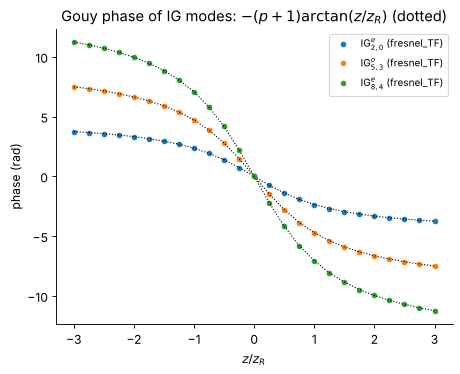

In [7]:
# Gouy phase: propagate numerically and compare with the analytic mode
# without its Gouy factor exp(-i*(p + 1)*psi)
zs = np.linspace(-3, 3, 25)*Z_R
for parity, p, m in [("even", 2, 0), ("odd", 5, 3), ("even", 8, 4)]:
    a0 = ince.ig_mode(p, m, eps, xb, yb, W0, WL, parity=parity)
    phase = []
    for z in zs:
        u = fresnel_TF(a0, xb, yb, z, WL)[0]
        psi = np.arctan(z/Z_R)
        no_gouy = ince.ig_mode(p, m, eps, xb, yb, W0, WL, z=z, parity=parity)*np.exp(1j*(p + 1)*psi)
        phase.append(np.angle(np.sum(u*np.conj(no_gouy))))
    phase = np.unwrap(phase)
    plt.plot(zs/Z_R, phase - phase[len(zs)//2], "o", ms=4, label=label(parity, p, m) + " (fresnel_TF)")
    plt.plot(zs/Z_R, -(p + 1)*np.arctan(zs/Z_R), "k:", lw=1)
plt.xlabel("$z/z_R$"); plt.ylabel("phase (rad)")
plt.title(r"Gouy phase of IG modes: $-(p+1)\arctan(z/z_R)$ (dotted)")
plt.legend(fontsize=9)

The numerical fields agree with `ince.ig_mode()` to $10^{-8}$ of the peak, and
the phase relative to the mode without its Gouy factor follows
$-(p+1)\arctan(z/z_R)$, the same law as for HG and LG modes of order $p$
(notebook [06 (Gaussian beams)](06_gaussian_beams.ipynb), section 3).

## 5. Through ABCD systems

Because the IG mode is a sum of HG modes of one order, the argument of
section 4 carries over to every first-order system with the same matrix in
$x$ and $y$: each HG part goes to the HG mode of the transformed beam
parameter $q' = (Aq + B)/(Cq + D)$ and picks up the same Gouy phase
$(p+1)\psi_{sys}$, with $\psi_{sys} = -\arg(A + B/q)$ from
`abcd.gouy_phase()`. So

$$\mathrm{IG}_{p,m}(\varepsilon; q) \;\xrightarrow{\ ABCD\ }\;
e^{-i(p+1)\psi_{sys}}\,\mathrm{IG}_{p,m}(\varepsilon; q'),$$

with the same $\varepsilon$: the foci scale with the beam. We send a
collimated $\mathrm{IG}^e_{6,2}$ mode through a lens with $f = 2$ m and look at
planes around the focus with `abcd.collins()`, the Collins integral of
notebook [08 (ABCD matrices)](08_abcd_matrices.ipynb), section 7. The reference is the IG
mode of $q'$, including its Gouy phase. The same holds for complex
matrices (Gaussian apertures), since the argument only needs the ABCD law
for $q$ and a common Gouy phase; we do not show it here.

 z (mm)   w(z) (um)   |overlap| with the IG mode of q_out   phase error (rad)
  1700      373.8     1.00000000                         +1.4e-11
  1900      386.0     1.00000000                         +3.4e-11
  2000      402.9     1.00000000                         -1.8e-10
  2100      425.9     1.00000000                         -3.2e-12
  2300      487.0     1.00000000                         -2.6e-10


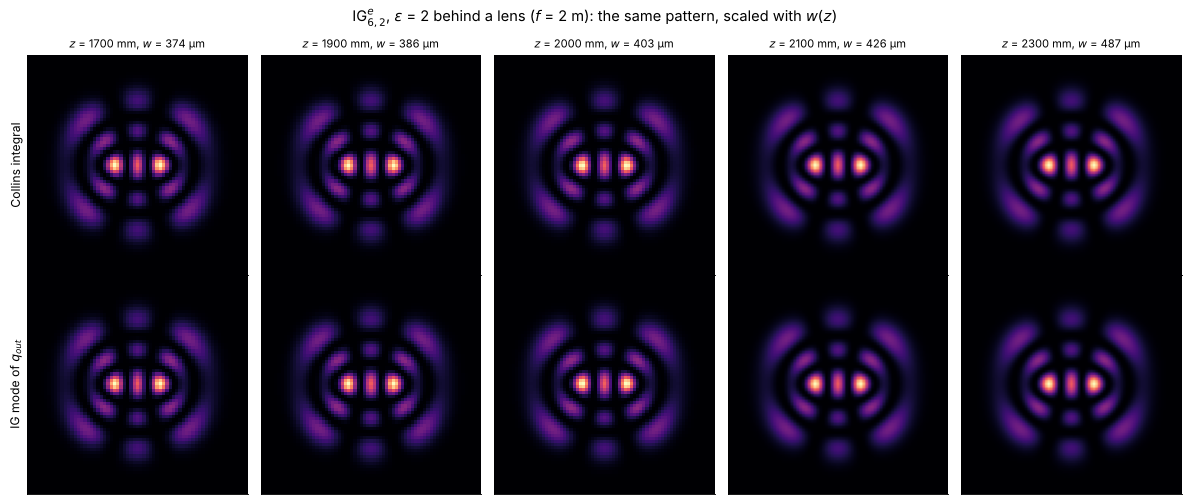

In [8]:
F = 2000.0                                  # lens (mm); a collimated IG mode with w0 = 1 mm at the lens
p, m, eps = 6, 2, 2.0
q_in = abcd.q_from_waist(W0, 0.0, WL)
u_in = ince.ig_mode(p, m, eps, x, y, W0, WL)
z_planes = np.array([1700.0, 1900.0, 2000.0, 2100.0, 2300.0])
fig, axes = plt.subplots(2, len(z_planes), figsize=(15, 6.4))
print(" z (mm)   w(z) (um)   |overlap| with the IG mode of q_out   phase error (rad)")
for j, zz in enumerate(z_planes):
    M = abcd.compose(abcd.thin_lens(F), abcd.free_space(zz))
    u = abcd.collins(u_in, x, y, M, WL)
    q_out = abcd.transform_q(M, q_in)
    w0_out, z_waist = abcd.waist(q_out, WL)
    # IG mode of the transformed q; collins() omits exp(i*k*L), so we drop exp(i*k*z) as well
    ref = ince.ig_mode(p, m, eps, x, y, w0_out, WL, z=-z_waist)*np.exp(2j*np.pi/WL*z_waist)
    c = overlap(u, ref)
    psi_sys = abcd.gouy_phase(M, q_in)           # Gouy phase of the system
    psi_ref = np.arctan2(-z_waist, np.imag(q_out))  # the one already in ref
    w = abcd.beam_radius(q_out, WL)
    print("{:6.0f}   {:8.1f}     {:.8f}                         {:+.1e}".format(
        zz, 1e3*w, abs(c), np.angle(c*np.exp(1j*(p + 1)*(psi_sys - psi_ref)))))
    for row, img in ((0, np.abs(u)**2), (1, np.abs(ref)**2)):
        ax = axes[row, j]
        ax.imshow(img/img.max(), extent=EXT, cmap="magma")
        ax.set_xlim(-3.5*w, 3.5*w); ax.set_ylim(-3.5*w, 3.5*w)
        ax.set_xticks([]); ax.set_yticks([])
    axes[0, j].set_title("$z$ = %.0f mm, $w$ = %.0f µm" % (zz, 1e3*w), fontsize=10)
axes[0, 0].set_ylabel("Collins integral"); axes[1, 0].set_ylabel(r"IG mode of $q_{out}$")
fig.suptitle(label("even", p, m, eps) + r" behind a lens ($f$ = 2 m): the same pattern, scaled with $w(z)$")
fig.tight_layout()

The overlap is 1 to eight digits in every plane, and the remaining phase
after removing $(p+1)\psi_{sys}$ is below $10^{-9}$ rad. The focus pattern
is the input pattern, only smaller. (The smallest spot lies a little before
$z = f$, the Gaussian focal shift of notebook [08 (ABCD matrices)](08_abcd_matrices.ipynb), section 6.)

A stable lens waveguide is the unfolded version of a resonator. An IG mode
built on the eigen beam of one cell reproduces itself after every cell,
with the phase $(p+1)$ times the Gouy phase of the cell. This is why IG
modes can be resonator modes: in a resonator, all modes of one order are
degenerate in frequency, and a small perturbation with elliptic symmetry
picks the IG combinations out of them (Bandres and Gutiérrez-Vega 2004,
Schwarz et al. 2004).

In [9]:
# a lens waveguide: 20 cells of f = 1 m lenses spaced by 1.5 m (stable, g = -0.5 per half cell)
cell = abcd.compose(abcd.free_space(1500.0), abcd.thin_lens(1000.0))
q_cell = abcd.eigenmode(cell)                # at the input of a cell, i.e. just behind a lens
w0_cell, z_cell = abcd.waist(q_cell, WL)
print("eigen beam of the cell: w = {:.3f} mm at the lenses".format(abcd.beam_radius(q_cell, WL)))
xg, yg, _, _ = grid2d(-4, 4, -4, 4, 256)
u = ince.ig_mode(4, 4, 3.0, xg, yg, w0_cell, WL, z=-z_cell, parity="odd")
u0 = u.copy()
gouy = []
for n in range(20):
    u = abcd.collins(u, xg, yg, cell, WL)
    c = np.sum(u*np.conj(u0))*(xg[1] - xg[0])**2
    gouy.append(np.angle(c))
print("|overlap| with the input after 20 cells: {:.8f}".format(abs(c)))
psi_cell = abcd.round_trip_gouy_phase(cell)
measured = -np.unwrap(gouy)/np.arange(1, 21)
print("phase per cell: measured {:.5f} rad, (p + 1)*psi_cell = {:.5f} rad (mod 2 pi)".format(
    np.mod(measured[-1], 2*np.pi), np.mod(5*psi_cell, 2*np.pi)))

eigen beam of the cell: w = 0.559 mm at the lenses


|overlap| with the input after 20 cells: 1.00000000
phase per cell: measured 0.30740 rad, (p + 1)*psi_cell = 0.30740 rad (mod 2 pi)


The field after 20 cells has the overlap 1 with the input (to eight
digits), and the phase per cell is $(p+1)\psi_{cell}$, here for
$\mathrm{IG}^o_{4,4}$ with $p + 1 = 5$.

## 6. Helical IG modes

The combinations

$$\mathrm{HIG}^\pm_{p,m} = \left(\mathrm{IG}^e_{p,m} \pm i\,\mathrm{IG}^o_{p,m}\right)/\sqrt2$$

(`ince.helical_ig_mode()`) generalize the helical LG modes
$\mathrm{LG}_{p,\pm m}$. For $\varepsilon \to 0$ they carry one vortex of
charge $\pm m$ on the axis. For $\varepsilon > 0$ that vortex splits into $m$
vortices of charge $\pm 1$ that line up on the interfocal line: the odd mode
vanishes on that line ($\sinh n\xi = 0$ at $\xi = 0$), the even mode at the
$m$ zeros of $C_p^m(\eta)$ along it. The ring becomes an ellipse. We take
$p = m = 4$ (no dark ellipses), find the vortices with
`vortices.phase_singularities()` and compute the orbital angular momentum
with `vortices.mean_oam()` from notebook [69 (optical vortices)](69_optical_vortices.ipynb).

 eps    vortices (x in mm, charge)                       total charge   mean OAM per photon
0.001   (-0.06, +1), (-0.06, +1), (+0.06, +1), (+0.06, +1)  +4.000         4.000
  0.5   (-0.45, +1), (-0.18, +1), (+0.18, +1), (+0.45, +1)  +4.000         3.986
    2   (-0.84, +1), (-0.29, +1), (+0.29, +1), (+0.84, +1)  +4.000         3.754


    8   (-1.11, +1), (-0.37, +1), (+0.37, +1), (+1.11, +1)  +4.000         2.491


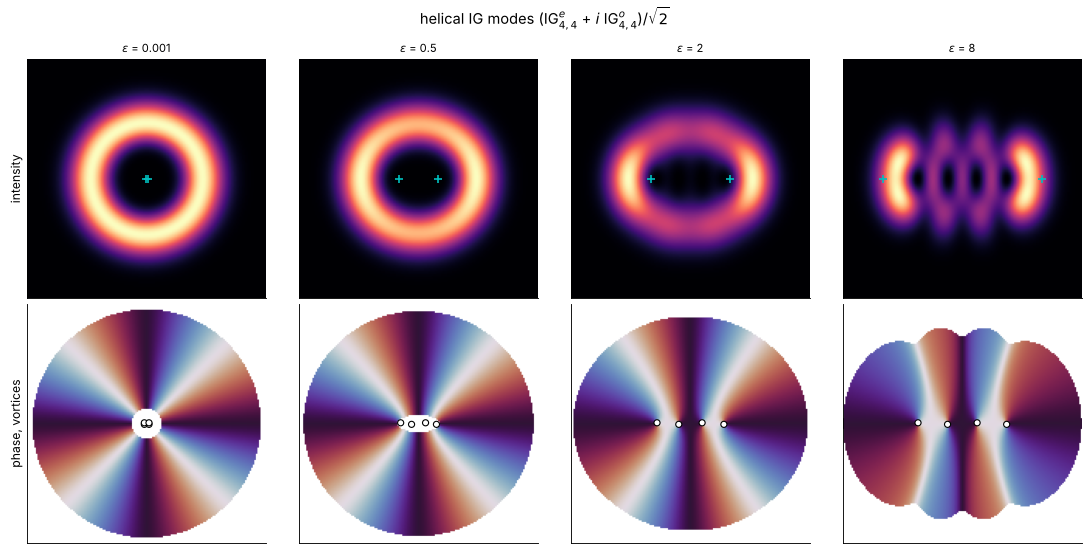

In [10]:
p, m = 4, 4
eps_list = [1e-3, 0.5, 2.0, 8.0]
fig, axes = plt.subplots(2, len(eps_list), figsize=(14, 7))
print(" eps    vortices (x in mm, charge)                       total charge   mean OAM per photon")
for j, eps in enumerate(eps_list):
    u = ince.helical_ig_mode(p, m, eps, x, y, W0, WL)
    f = np.sqrt(eps/2)*W0
    show_I(axes[0, j], u, r"$\varepsilon$ = %g" % eps, lim=3.0, foci=f)
    show_phase(axes[1, j], u, lim=3.0)
    xs, ys, qs = vortices.phase_singularities(u, x, y, threshold=1e-12, mask=(X**2 + Y**2) < 2.5**2)
    axes[1, j].scatter(xs, ys, c=["w" if q > 0 else "k" for q in qs], s=30, edgecolors="k")
    total = vortices.topological_charge(u, x, y, radius=3.0)
    print("{:5g}   {:50s}  {:+.3f}         {:.3f}".format(
        eps, ", ".join("({:+.2f}, {:+d})".format(a, int(q)) for a, q in sorted(zip(xs, qs))),
        total, vortices.mean_oam(u, x, y)))
axes[0, 0].set_ylabel("intensity"); axes[1, 0].set_ylabel("phase, vortices")
fig.suptitle(r"helical IG modes (IG$^e_{4,4}$ + $i$ IG$^o_{4,4}$)/$\sqrt{2}$")
fig.tight_layout()

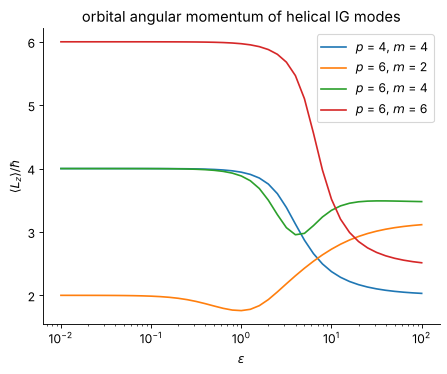

In [11]:
eps_axis = np.geomspace(1e-2, 1e2, 41)
for p, m in [(4, 4), (6, 2), (6, 4), (6, 6)]:
    oam = [vortices.mean_oam(ince.helical_ig_mode(p, m, e, x, y, W0, WL), x, y) for e in eps_axis]
    plt.plot(eps_axis, oam, label=r"$p$ = %d, $m$ = %d" % (p, m))
plt.xscale("log"); plt.xlabel(r"$\varepsilon$"); plt.ylabel(r"$\langle L_z\rangle/\hbar$")
plt.title("orbital angular momentum of helical IG modes")
plt.legend()

All four vortices have the charge +1, and they move outwards along the
interfocal line as $\varepsilon$ grows; the total charge on a large circle
stays 4. The OAM per photon does not: it falls from $4\hbar$ to $3.75\hbar$
at $\varepsilon = 2$ and $2.5\hbar$ at $\varepsilon = 8$. The mode is no longer
an eigenmode of $L_z$, since its LG content spreads over several $l$
(section 3). For large $\varepsilon$ it tends to a combination of two HG
modes with a phase shift of $\pi/2$, whose OAM depends on $p$ and $m$.

## 7. Where it stops: astigmatic systems

A cylindrical lens has different matrices in $x$ and $y$. HG modes aligned
with its axes are still modes of such a system, but each one picks up the
Gouy phase $(l + \frac12)\psi_x + (m + \frac12)\psi_y$. The parts of an IG
mode, $\sum_l c_l\,\mathrm{HG}_{l,p-l}$, then get the relative phases
$l\,(\psi_x - \psi_y)$, and the sum is no longer the same pattern. We put
a cylindrical lens ($f = 1$ m, power in $x$) at the waist of
$\mathrm{IG}^e_{6,2}$ and compare the Collins integral (`collins()` with
separate matrices for $x$ and $y$) with that sum, built from 1D HG modes
with their own $q_x$, $q_y$ and Gouy phases. The axes are scaled with $w_x$ and
$w_y$, so that the trivial stretch of the beam is taken out and only the
change of the pattern remains.

 z (mm)   w_x (mm)   w_y (mm)   psi_x - psi_y (rad)   |overlap| with the separable prediction
   500     0.510      1.005    +0.098                1.00000000
   800     0.257      1.013    +0.518                1.00000000
  1050     0.217      1.022    +1.595                1.00000000
  2000     1.078      1.078    +2.376                1.00000000


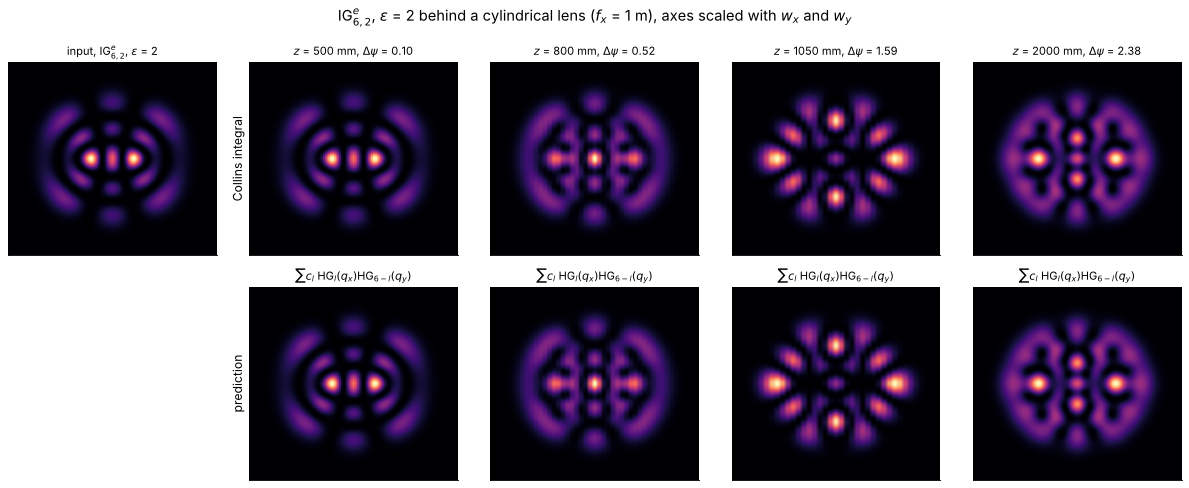

In [12]:
def hg_1d(l, s, q, psi, wl):
    """1D Hermite-Gaussian with beam parameter q and the Gouy phase (l + 1/2)*psi."""
    w = abcd.beam_radius(q, wl)
    k = 2*np.pi/wl
    return ((2/np.pi)**0.25/np.sqrt(2**l*factorial(l)*w)*eval_hermite(l, np.sqrt(2)*s/w)
            *np.exp(1j*k*s**2/(2*np.conj(q)) - 1j*(l + 0.5)*psi))


def separable_prediction(coeffs, q_in, M_x, M_y, s_x, s_y, wl):
    """sum c_l HG_l(x; q_x) HG_(p-l)(y; q_y), each axis with its own Gouy phase."""
    qx, qy = abcd.transform_q(M_x, q_in), abcd.transform_q(M_y, q_in)
    psi_x, psi_y = abcd.gouy_phase(M_x, q_in), abcd.gouy_phase(M_y, q_in)
    return sum(c*np.outer(hg_1d(n, s_y, qy, psi_y, wl), hg_1d(l, s_x, qx, psi_x, wl))
               for (l, n), c in coeffs.items())


def show_scaled(ax, u, w_x, w_y, title=None, lim=3.5):
    I = np.abs(u)**2
    ax.imshow(I/I.max(), extent=[x[0]/w_x, x[-1]/w_x, y[0]/w_y, y[-1]/w_y], cmap="magma", aspect="auto")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=10)


F_c = 1000.0                          # cylindrical lens with power in x, at the waist
p, m, eps = 6, 2, 2.0
u_in = ince.ig_mode(p, m, eps, x, y, W0, WL)
coeffs = ince.hg_coefficients(p, m, eps)
z_list = [500.0, 800.0, 1050.0, 2000.0]
fig, axes = plt.subplots(2, len(z_list) + 1, figsize=(15, 6.2))
show_scaled(axes[0, 0], u_in, W0, W0, "input, " + label("even", p, m, eps))
axes[1, 0].axis("off")
print(" z (mm)   w_x (mm)   w_y (mm)   psi_x - psi_y (rad)   |overlap| with the separable prediction")
for j, zz in enumerate(z_list):
    M_x = abcd.compose(abcd.thin_lens(F_c), abcd.free_space(zz))
    M_y = abcd.free_space(zz)
    u = abcd.collins(u_in, x, y, M_x, WL, M_y=M_y)
    w_x = abcd.beam_radius(abcd.transform_q(M_x, q_in), WL)
    w_y = abcd.beam_radius(abcd.transform_q(M_y, q_in), WL)
    pred = separable_prediction(coeffs, q_in, M_x, M_y, x, y, WL)
    dpsi = abcd.gouy_phase(M_x, q_in) - abcd.gouy_phase(M_y, q_in)
    show_scaled(axes[0, j + 1], u, w_x, w_y, r"$z$ = %.0f mm, $\Delta\psi$ = %.2f" % (zz, dpsi))
    show_scaled(axes[1, j + 1], pred, w_x, w_y, r"$\sum c_l$ HG$_l(q_x)$HG$_{6-l}(q_y)$")
    print("{:6.0f}   {:7.3f}    {:7.3f}    {:+.3f}                {:.8f}".format(
        zz, w_x, w_y, dpsi, abs(overlap(u, pred))))
axes[0, 1].set_ylabel("Collins integral"); axes[1, 1].set_ylabel("prediction")
fig.suptitle(label("even", p, m, eps) + r" behind a cylindrical lens ($f_x$ = 1 m), axes scaled with $w_x$ and $w_y$")
fig.tight_layout()

The sum of HG modes with separate Gouy phases describes the field exactly
(overlap 1 to eight digits), but the pattern is no longer an IG mode once the
Gouy phase difference $\Delta\psi = \psi_x - \psi_y$ is a sizeable fraction
of $\pi$. Only the $\varepsilon \to \infty$ limit, a single HG mode aligned with
the cylinder axes, survives an astigmatic system unchanged. A rotated
cylindrical lens mixes $x$ and $y$ and breaks even that; such general
astigmatic systems, and the twisted beams they make, are in notebook
[08 (ABCD matrices)](08_abcd_matrices.ipynb), sections 11 and 12. A matched pair of cylindrical lenses with
$\Delta\psi = \pi/2$ is the mode converter of notebook
[69 (optical vortices)](69_optical_vortices.ipynb), section 7, which turns HG
modes at 45° into LG modes.

## Summary

- IG modes $\mathrm{IG}^{e,o}_{p,m}(\varepsilon)$ separate the paraxial wave
  equation in elliptic coordinates with foci at $\pm\sqrt{\varepsilon/2}\,w(z)$.
  `ince.ince_series()` computes the Ince polynomials as a small eigenvalue
  problem, `ince.ig_mode()` the normalized modes, which run from LG modes
  ($\varepsilon \to 0$) to HG modes ($\varepsilon \to \infty$) and are
  orthonormal and complete.
- Each IG mode of order $p$ is a finite sum of HG or LG modes of order $p$
  (`ince.hg_coefficients()`, `ince.lg_coefficients()`, exact by
  Gauss-Hermite quadrature; the numerical decomposition of notebook 09
  (mode analysis) agrees to $10^{-13}$).
- So it keeps its shape in free space with the Gouy phase $(p+1)\psi$, and in
  every ABCD system that treats $x$ and $y$ alike: transform $q$, keep
  $\varepsilon$, multiply by $e^{-i(p+1)\psi_{sys}}$. A lens focus and a
  lens waveguide confirm it to eight digits. This is also why IG modes can
  be the modes of stable resonators.
- Helical IG modes carry $m$ unit vortices on the interfocal line; their
  total charge is $m$, while their OAM per photon drops below $m\hbar$ as
  $\varepsilon$ grows.
- In astigmatic systems the HG parts pick up different Gouy phases and the
  IG pattern falls apart; only aligned HG modes survive. General
  astigmatism is treated in notebook 08 (ABCD matrices), sections 11 and 12.

## References

- E. L. Ince, "A linear differential equation with periodic coefficients", Proc. London Math. Soc. 23, 56-74 (1925).
- M. A. Bandres and J. C. Gutiérrez-Vega, "Ince-Gaussian beams", Opt. Lett. 29, 144-146 (2004).
- M. A. Bandres and J. C. Gutiérrez-Vega, "Ince-Gaussian modes of the paraxial wave equation and stable resonators", J. Opt. Soc. Am. A 21, 873-880 (2004).
- U. T. Schwarz, M. A. Bandres and J. C. Gutiérrez-Vega, "Observation of Ince-Gaussian modes in stable resonators", Opt. Lett. 29, 1870-1872 (2004).
- J. B. Bentley, J. A. Davis, M. A. Bandres and J. C. Gutiérrez-Vega, "Generation of helical Ince-Gaussian beams with a liquid-crystal display", Opt. Lett. 31, 649-651 (2006).
- S. A. Collins, "Lens-system diffraction integral written in terms of matrix optics", J. Opt. Soc. Am. 60, 1168-1177 (1970).
- A. E. Siegman, "Lasers", University Science Books (1986).

In [13]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 22 s
